# Kazakh Profanity Detection
Input: one Kazakh comment. Output: `0` = no profanity, `1` = profanity (+ probability).

**The plan in 7 steps** (one section each):
1. Load data  →  2. Clean text  →  3. Split train / val / test (no leaks)  →  4. Add a few synthetic "hard" examples to *train*  →
  5. Baseline model (TF-IDF)  →  6. Main model: fine-tune XLM-RoBERTa  →  7. Test **once**, look at errors, save, predict.

Rules we follow: every choice (epochs, threshold, which model) is made on the **validation** set. The **test** set is touched only once at the end.

Run on Google Colab with a GPU: *Runtime → Change runtime type → T4 GPU*, then *Run all*.

## 0. Setup

In [39]:
!pip -q install transformers scikit-learn openpyxl joblib seaborn

In [55]:
import os, re, json, random, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline, make_union
from sklearn.metrics import f1_score, precision_recall_fscore_support, confusion_matrix, classification_report

SEED       = 42
DATA_FILE  = 'kazakh_profanity_share.xlsx'
MODEL_NAME = 'xlm-roberta-base'                   # pretrained model
MAX_LEN    = 128                                  # 128 tokens
EPOCHS, BATCH_SIZE, LR = 10, 16, 3e-5
OUT_DIR    = 'artifacts'

random.seed(SEED); np.random.seed(SEED)
os.makedirs(OUT_DIR, exist_ok=True)

## 1. Load the data

In [41]:
data = pd.read_excel(DATA_FILE)
data['text'] = data['text'].astype(str)
print(data.shape)
print(data['label'].value_counts())      # 0 = clean, 1 = profanity
data.sample(5, random_state=1)[['text', 'label']]

(3061, 4)
label
1    1566
0    1495
Name: count, dtype: int64


,text,label
1658,Неге осыдан сабак отеды мектеп те дурыс еды го,0
45,Суска төмен нашар қотақбас наху брт сұмырвй түспейді шешеңнің амы,1
1266,Керемет екен маған ұнады Кім біледі не наху пидараз не наху пидараз не наху,1
6,Шешенің амы малдар каждый онда рекламада осы ғана кет нахуй,1
2336,"Күшті, өтте ыңғайлы. Алла сендерді қолдасын.",0


## 2. Clean the text
People write the same word in many ways: `қотақ`, `котак`, `QOTAQ`, `қотттақ`, or in Latin letters `qotaq`. We make them look alike.

Two cleaners (saved in `kz_text.py` so that prediction later uses *exactly* the same code):
* `clean_for_bert(text)` – light cleaning for the transformer: lower-case, remove links / emoji, shorten long repeats (`өтттте` → `өтте`). Kazakh letters are kept because the pretrained model knows them.
* `clean_for_tfidf(text)` – stronger cleaning for the simple model: also turns Latin letters into Cyrillic and replaces Kazakh-only letters by Russian ones (`қ→к`, `ғ→г`, `ү→у` …), so all spellings become one.

In [42]:
%%writefile kz_text.py
import re, unicodedata

LATIN_TO_CYR = {'sh':'ш','ch':'ч','ya':'я','yu':'ю','a':'а','á':'ә','b':'б','d':'д','e':'е','f':'ф','g':'г','ǵ':'ғ',
                'h':'х','i':'і','ı':'и','j':'ж','k':'к','l':'л','m':'м','n':'н','ń':'ң','o':'о','ó':'ө','p':'п','q':'қ',
                'r':'р','s':'с','t':'т','u':'ұ','ú':'ү','v':'в','w':'у','x':'х','y':'ы','ý':'у','z':'з','c':'к'}
KAZAKH_TO_RUSSIAN = str.maketrans({'ә':'а','ғ':'г','қ':'к','ң':'н','ө':'о','ұ':'у','ү':'у','һ':'х','і':'и','ё':'е','й':'и'})

def clean_for_bert(text):
    text = unicodedata.normalize('NFKC', str(text)).lower()
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)            # links
    text = re.sub('[\U0001F000-\U0001FAFF\u2600-\u27BF\uFE0F\u200d]', ' ', text)   # emoji
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)                     # өтттте -> өтте
    text = re.sub(r'[^\w\s\*#@$]', ' ', text)                      # punctuation -> space (keep masks * # @ $)
    return re.sub(r'\s+', ' ', text).strip()

def latin_to_cyrillic(text):
    out, i = '', 0
    while i < len(text):
        if text[i:i+2] in LATIN_TO_CYR:   out += LATIN_TO_CYR[text[i:i+2]]; i += 2    # two-letter sounds first (sh, ch)
        elif text[i] in LATIN_TO_CYR:     out += LATIN_TO_CYR[text[i]];     i += 1
        else:                             out += text[i];                    i += 1
    return out

def clean_for_tfidf(text):
    text = latin_to_cyrillic(clean_for_bert(text)).translate(KAZAKH_TO_RUSSIAN)
    text = re.sub(r'(.)\1+', r'\1', text)
    return re.sub(r'\s+', ' ', text).strip()

Overwriting kz_text.py


In [43]:
from kz_text import clean_for_bert, clean_for_tfidf

examples = ['Ө тттте жақсы ойын!!! 👍', 'Qotaq oyin, ote nashar', 'ҚОТАҚ екен', 'Котак екен']

pd.DataFrame({'raw': examples, 'for_bert': map(clean_for_bert, examples), 'for_tfidf': map(clean_for_tfidf, examples)})

,raw,for_bert,for_tfidf
0,Ө тттте жақсы ойын!!! 👍,ө тте жақсы ойын,о те жаксы оиын
1,"Qotaq oyin, ote nashar",qotaq oyin ote nashar,котак оыин оте нашар
2,ҚОТАҚ екен,қотақ екен,котак екен
3,Котак екен,котак екен,котак екен


## 3. Split: train / validation / test
* **Remove duplicates** – after cleaning, `Қотақ` and `котак` are the same comment, so keep one.
* **Near-duplicates stay together** – we give every group of very similar comments one `group` number, and the split never puts one group into two parts (otherwise the test set would contain copies of training comments and the score would be too good).
* Split sizes ≈ 71 % train / 14 % val / 14 % test, balanced by label, `random_state = 42`.

In [44]:
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold

data['bert_text']  = data['text'].map(clean_for_bert)
data['tfidf_text'] = data['text'].map(clean_for_tfidf)

# remove empty and duplicate comments
before = len(data)
data = data[data.tfidf_text != ''].drop_duplicates('tfidf_text').reset_index(drop=True)
print('removed', before - len(data), 'empty/duplicate comments; left', len(data))

# group near-duplicates (cosine similarity of character n-grams >= 0.9)
vectors = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5)).fit_transform(data.tfidf_text)
similar = cosine_similarity(vectors) >= 0.9
data['group'] = connected_components(similar, directed=False)[1]

# split by group: fold 0 -> test, fold 1 -> validation, the rest -> train
folds = list(StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED).split(data, data.label, data.group))
data['split'] = 'train'
data.loc[folds[0][1], 'split'] = 'test'
data.loc[folds[1][1], 'split'] = 'val'

train = data[data.split == 'train'].reset_index(drop=True)
val   = data[data.split == 'val'].reset_index(drop=True)
test  = data[data.split == 'test'].reset_index(drop=True)

print(pd.crosstab(data.split, data.label, margins=True))

assert not set(train.group) & set(val.group) and not set(train.group) & set(test.group) and not set(val.group) & set(test.group)

data[['kazsandra_id', 'label', 'split']].to_csv(f'{OUT_DIR}/splits.csv', index=False)

removed 22 empty/duplicate comments; left 3039
label     0     1   All
split                  
test    201   228   429
train  1076  1102  2178
val     217   215   432
All    1494  1545  3039


## 4. Synthetic "hard" examples
The word `қатын` is tricky: it is an insult in our labeling rule, but it also looks like
* `қатты` ("very"): *Маған қатын ұнады* is may be typo, but we consider it as it is,
* the verb `қатынау` ("to commute"): *үйге қатынайын дедім* → clean.

The real data has too few such comments, so we make a few **synthetic** ones and add them to the **training set only** (never to val/test). They are saved to `synthetic_train_examples.csv`

In [45]:
def make_synthetic(train_df):
    rng = random.Random(SEED)
    clean = train_df[train_df.label == 0]
    short_clean = clean[clean.text.str.split().str.len().between(3, 10)].text.tolist()
    rows = []

    # the verb "қатынау" (to commute) -> clean (0)
    places = ['үйге', 'жұмысқа', 'қалаға', 'мектепке', 'университетке']
    verbs  = ['қатынайын дедім', 'қатынаймын', 'қатынайды', 'қатынап жүрмін', 'қатынайтын автобус аз', 'қатынайтын көлік жоқ']
    for place in places:
        for verb in verbs:
            rows.append((f'{place} {verb}', 0, 'verb_qatynau'))
            rows.append((f'{place} {verb} ' + clean_for_bert(rng.choice(short_clean)), 0, 'verb_qatynau'))

    # a clean comment + an insulting ending -> profanity (1)
    endings = ['орыс қатын', 'мал қатын', 'ұрысқақ қатындар', 'қатын екенсің', 'осы қатындар', 'жаман қатын']
    for text in rng.sample(short_clean, 60):
        rows.append((clean_for_bert(text) + ' ' + rng.choice(endings), 1, 'insult_ending'))

    syn = pd.DataFrame(rows, columns=['text', 'label', 'kind'])
    syn['bert_text']  = syn.text.map(clean_for_bert)
    syn['tfidf_text'] = syn.text.map(clean_for_tfidf)
    return syn

synthetic = make_synthetic(train)
synthetic.to_csv('synthetic_train_examples.csv', index=False)
train_plus = pd.concat([train, synthetic], ignore_index=True)       # used ONLY for fitting models
print(synthetic.kind.value_counts().to_string())
print('train:', len(train), 'real +', len(synthetic), 'synthetic =', len(train_plus))

kind
verb_qatynau     60
insult_ending    60
train: 2178 real + 120 synthetic = 2298


## 5. Baseline: TF-IDF + logistic regression
TF-IDF counts how important character pieces and words are; logistic regression learns a weight for each. It is quick and a good yardstick for the big model.
We keep the best `C` (regularisation strength) by **validation** F1.

In [46]:
def best_threshold(y_true, prob):
    # try thresholds 0.10 ... 0.90 and return the one with the best F1 (we use VALIDATION data for this)
    best = max(((f1_score(y_true, prob >= t), t) for t in np.arange(0.10, 0.91, 0.01)))
    return best[1], best[0]

best_f1 = -1
for C in [3, 10, 30, 100]:
    candidate = make_pipeline(
        make_union(TfidfVectorizer(analyzer='char_wb', ngram_range=(1, 4), sublinear_tf=True, min_df=2),   # pieces of words
                   TfidfVectorizer(analyzer='word', ngram_range=(1, 2), sublinear_tf=True)),               # whole words and word pairs
        LogisticRegression(C=C, max_iter=3000))
    candidate.fit(train_plus.tfidf_text, train_plus.label)          # fit on TRAIN only
    f1 = f1_score(val.label, candidate.predict(val.tfidf_text))
    print(f'C={C:<4} validation F1 = {f1:.4f}')
    if f1 > best_f1: best_f1, baseline = f1, candidate

val_prob_baseline = baseline.predict_proba(val.tfidf_text)[:, 1]

C=3    validation F1 = 0.9171
C=10   validation F1 = 0.9197
C=30   validation F1 = 0.9227
C=100  validation F1 = 0.9253


## 6. Main model: fine-tune XLM-RoBERTa
**Why:** XLM-R was pre-trained on text in 100 languages including Kazakh, so it already "knows" Kazakh words and grammar. We only teach it our task (profanity or not) with our ~2 400 examples. A network trained from scratch cannot learn this from so little data.

**How a comment becomes model input:** cleaned text → tokenizer splits it into word pieces (an unknown word is just split into smaller known pieces, so there are no "unknown word" problems) → numbers → padded/cut to 128 tokens → model outputs 2 scores (clean / profanity) → softmax gives the probability.

**Training:** cross-entropy loss, AdamW optimizer, learning rate slowly decreasing. After every epoch we measure F1 on validation and keep the best epoch.

In [47]:
import torch
from torch.utils.data import TensorDataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('using', device)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def make_loader(texts, labels, shuffle):
    enc = tokenizer(list(texts), truncation=True, max_length=MAX_LEN, padding='max_length', return_tensors='pt')
    dataset = TensorDataset(enc['input_ids'], enc['attention_mask'], torch.tensor(list(labels)))
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle)

train_loader = make_loader(train_plus.bert_text, train_plus.label, shuffle=True)
val_loader   = make_loader(val.bert_text,        val.label,        shuffle=False)
test_loader  = make_loader(test.bert_text,       test.label,       shuffle=False)

def get_probabilities(model, loader):
    # probability of class 1 (profanity) for every comment in the loader
    model.eval(); probs = []
    with torch.no_grad():
        for ids, mask, _ in loader:
            logits = model(input_ids=ids.to(device), attention_mask=mask.to(device)).logits
            probs.append(torch.softmax(logits, dim=-1)[:, 1].cpu().numpy())
    return np.concatenate(probs)

using cuda


In [56]:
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
total_steps = EPOCHS * len(train_loader)
scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)

patience, bad_epochs = 2, 0

best_val_f1 = -1
for epoch in range(1, EPOCHS + 1):
    model.train(); total_loss = 0
    for ids, mask, labels in train_loader:
        out = model(input_ids=ids.to(device), attention_mask=mask.to(device), labels=labels.to(device))
        out.loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)      # avoids exploding gradients
        optimizer.step(); scheduler.step(); optimizer.zero_grad()
        total_loss += out.loss.item()

    val_prob_bert = get_probabilities(model, val_loader)
    val_f1 = f1_score(val.label, val_prob_bert >= 0.5)
    print(f'epoch {epoch}: train loss {total_loss/len(train_loader):.4f} | validation F1 {val_f1:.4f}')
    if val_f1 > best_val_f1:
        best_val_f1, bad_epochs = val_f1, 0
        model.save_pretrained(f'{OUT_DIR}/bert_model'); tokenizer.save_pretrained(f'{OUT_DIR}/bert_model')
    else:
        bad_epochs += 1
        if bad_epochs >= patience:
            print('early stop'); break

model = AutoModelForSequenceClassification.from_pretrained(f'{OUT_DIR}/bert_model').to(device)   # reload the best epoch
val_prob_bert = get_probabilities(model, val_loader)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1: train loss 0.6327 | validation F1 0.8161


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

epoch 2: train loss 0.6416 | validation F1 0.7728
epoch 3: train loss 0.4385 | validation F1 0.8601


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (4 outputs left out)

epoch 6: train loss 0.1521 | validation F1 0.9378


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

epoch 7: train loss 0.1188 | validation F1 0.9336
epoch 8: train loss 0.0792 | validation F1 0.9324
early stop


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

## 7. Choose the final model and threshold
Two candidates: **A** = XLM-R alone, **B** = TF-IDF probabilities.

For each, we find the best decision threshold on validation. The one with the higher validation F1 is the final model.

In [70]:
thr_a, f1_a = best_threshold(val.label.values, val_prob_bert)
thr_b, f1_b = best_threshold(val.label.values, val_prob_baseline)
print(f'A  XLM-R alone      : threshold {thr_a:.2f}, validation F1 {f1_a:.4f}')
print(f'B  TF-IDF           : threshold {thr_b:.2f}, validation F1 {f1_b:.4f}')

FINAL = {'threshold': float(thr_a), 'max_len': MAX_LEN, 'seed': SEED}
print('FINAL:', FINAL)

joblib.dump(baseline, f'{OUT_DIR}/tfidf_model.joblib')
json.dump(FINAL, open(f'{OUT_DIR}/config.json', 'w'), indent=2)
import shutil; shutil.copy('kz_text.py', OUT_DIR)

A  XLM-R alone      : threshold 0.77, validation F1 0.9400
B  TF-IDF           : threshold 0.38, validation F1 0.9333
FINAL: {'threshold': 0.7699999999999997, 'max_len': 128, 'seed': 42}


'artifacts/kz_text.py'

## 8. Final evaluation on the TEST set
Class `1` (profanity) is the "positive" class.
* **Precision** = of the comments we flagged, how many were really profane.
* **Recall** = of the really profane comments, how many we found.
* **F1** = balance of both.
* **False positive** = a clean comment flagged as profane (a normal customer's review gets blocked).
* **False negative** = a profane comment that slips through (abuse gets published).

TEST (n=429)  precision=0.9427  recall=0.9386  F1=0.9407

              precision    recall  f1-score   support

     0 clean     0.9307    0.9353    0.9330       201
 1 profanity     0.9427    0.9386    0.9407       228

    accuracy                         0.9371       429
   macro avg     0.9367    0.9370    0.9368       429
weighted avg     0.9371    0.9371    0.9371       429



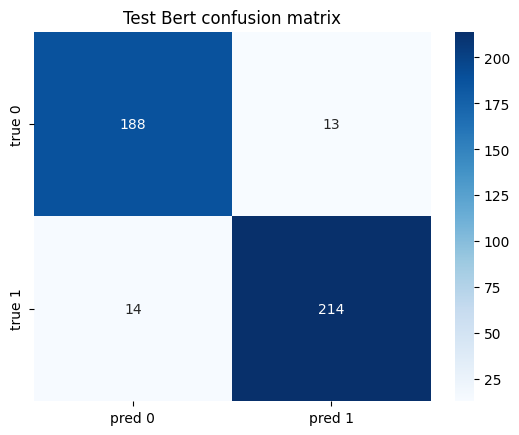

TF-IDF baseline alone, test F1: 0.9336


In [75]:
test_prob    = get_probabilities(model, test_loader)
test_prob_baseline = baseline.predict_proba(test.tfidf_text)[:, 1]
test_pred = (test_prob >= FINAL['threshold']).astype(int)

p, r, f, _ = precision_recall_fscore_support(test.label, test_pred, labels=[1], zero_division=0)
print(f'TEST (n={len(test)})  precision={p[0]:.4f}  recall={r[0]:.4f}  F1={f[0]:.4f}\n')
print(classification_report(test.label, test_pred, target_names=['0 clean', '1 profanity'], digits=4))

cm = confusion_matrix(test.label, test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['pred 0', 'pred 1'], yticklabels=['true 0', 'true 1'])
plt.title('Test Bert confusion matrix'); plt.savefig(f'{OUT_DIR}/confusion_matrix.png', dpi=150, bbox_inches='tight'); plt.show()

json.dump({'n_test': len(test), 'precision': p[0], 'recall': r[0], 'f1': f[0], 'confusion_matrix': cm.tolist()},
          open(f'{OUT_DIR}/test_metrics.json', 'w'), indent=2, default=float)

# for comparison only: the baseline alone
print('TF-IDF baseline alone, test F1:', round(f1_score(test.label, test_prob_baseline >= thr_b), 4))


              precision    recall  f1-score   support

     0 clean     0.9171    0.9353    0.9261       201
 1 profanity     0.9420    0.9254    0.9336       228

    accuracy                         0.9301       429
   macro avg     0.9295    0.9304    0.9299       429
weighted avg     0.9303    0.9301    0.9301       429



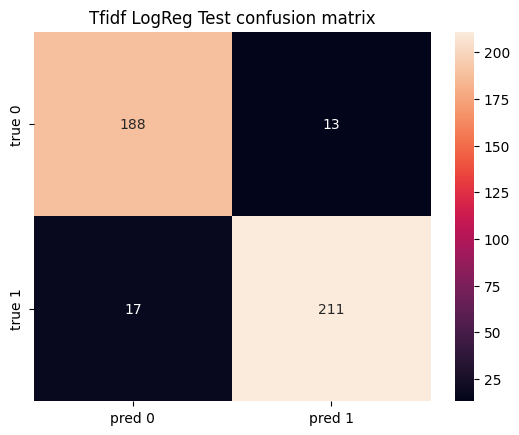

In [78]:
print(classification_report(test.label,  test_prob_baseline >= thr_b, target_names=['0 clean', '1 profanity'], digits=4))
cm = confusion_matrix(test.label, test_prob_baseline >= thr_b)
sns.heatmap(cm, annot=True, fmt='d', xticklabels=['pred 0', 'pred 1'], yticklabels=['true 0', 'true 1'])
plt.title('Tfidf LogReg Test confusion matrix');


## 9. Look at the mistakes

In [59]:
pd.set_option('display.max_colwidth', 120)
result = test.assign(probability=test_prob.round(3), predicted=test_pred)

print('FALSE NEGATIVES (profane, but we said clean):')
display(result[(result.label == 1) & (result.predicted == 0)][['text', 'probability']].sort_values('probability').head(10))

print('FALSE POSITIVES (clean, but we said profane):')
display(result[(result.label == 0) & (result.predicted == 1)][['text', 'probability']].sort_values('probability', ascending=False).head(10))

FALSE NEGATIVES (profane, but we said clean):


,text,probability
172,Маған ұнамады өте нашар өтірікшілер малар,0.003
120,Добрый вечёр вам дорогие рукожопы))) Я лучше спотифаю буду платить 5$/мес Ей адам деген биринши озин корсету керек к...,0.003
200,Өте керемет ампл жапмл Салам нолик,0.004
410,Корона вирус котынды кысып сен отырш быз емес,0.007
280,Есектер,0.010
100,өте күшті емес сука,0.011
209,Жаман екен оинап отканда шыгарып жебере берды жаман автор дб екен,0.011
427,Koti boq til istemet,0.015
91,Сіккккееннім барғооое,0.024
330,Есектердін ойнайтын ойыны.Бұл ойынды ойнамандар. Оданда Free Fire ойының ойнандар.,0.046


FALSE POSITIVES (clean, but we said profane):


,text,probability
15,Ай малдес топқой тик ток,0.999
105,Маңғыстауда мал жоқ па? Дым шықпайды ғой,0.999
405,Күшті Далпдвбр,0.999
393,Көнілім толмады чо то,0.999
289,Сөздік қорыңды көбейтуге жалпы кітап көмектеселі екен соны түсіндім. Сосын біз орысша араластырып шала сөйлегенге үй...,0.999
408,Адамның миын жегеннен басқа дым блмид екен😐👌,0.998
383,Керемет мен 9672кубок жеттим еди 10000кубокка жеткизейиндеп жатырмын менде 24 боец баска ештене туспейди маган амвер...,0.997
65,Ката беред,0.994
131,Оиын ұнады бырақ тек қана 1кнопка болғандықтан онша қызық болып табылмады және пенальти тосқанда қақпашыны қай жақа ...,0.991
173,Jaman oiyn eken,0.985


"Маңғыстауда мал жоқ па?" (0.999) is a clean sentence about livestock, and "Ай малдес топқой тик ток" (0.999) is also labeled clean. In the training data мал is mostly an insult, so the model learned a word-level shortcut. "Jaman oiyn eken" (0.985, "bad game") and "Ката беред" (0.994, a misspelling of "қате береді", "gives an error") are clean. The problem here: Latin script and misspellings. "Күшті Далпдвбр" (0.999) are hard even for a human, so some errors come from the labels rather than the model.

## 10. Predict on new text

In [65]:
def predict(texts, folder=OUT_DIR):
    """texts: one string or a list of strings  ->  list of {'label', 'probability', 'text'}"""
    import sys; sys.path.insert(0, folder)
    from kz_text import clean_for_bert, clean_for_tfidf
    config = json.load(open(f'{folder}/config.json'))
    tok = AutoTokenizer.from_pretrained(f'{folder}/bert_model')
    net = AutoModelForSequenceClassification.from_pretrained(f'{folder}/bert_model').to(device).eval()
    simple = joblib.load(f'{folder}/tfidf_model.joblib')

    texts = [texts] if isinstance(texts, str) else list(texts)
    enc = tok([clean_for_bert(t) for t in texts], truncation=True, max_length=config['max_len'], padding=True, return_tensors='pt').to(device)
    with torch.no_grad():
        prob = torch.softmax(net(**enc).logits, dim=-1)[:, 1].cpu().numpy()
  
    return [{'label': int(p >= config['threshold']), 'probability': round(float(p), 3), 'text': t} for p, t in zip(prob, texts)]

pd.DataFrame(predict([
    'Өте жақсы қолданба, ұнады',                       # clean, positive
    'Жаман ойын, қате береді, ақшаны қайтарыңдар',     # clean, but negative
    'Маған қатын ұнады',
    'hi уйге қатынайын дедим',
    'Орыс қатын жауап бермейді',                       # insult -> profanity
    'Ote jaqsy oiyn, rahmet',                          # Latin letters, clean
    'малский amazing work',                             # mixed with english -> profanity
    'мал шаруашылығына жақсы инструпент поидей'
]))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,label,probability,text
0,0,0.003,"Өте жақсы қолданба, ұнады"
1,0,0.003,"Жаман ойын, қате береді, ақшаны қайтарыңдар"
2,1,0.999,Маған қатын ұнады
3,0,0.003,hi уйге қатынайын дедим
4,1,0.999,Орыс қатын жауап бермейді
5,0,0.008,"Ote jaqsy oiyn, rahmet"
6,1,0.999,малский amazing work
7,0,0.003,мал шаруашылығына жақсы инструпент поидей
